# Satellite simulation walkthrough

## Goal

Follow one example from scheduled observations to packet delivery, stochastic fault analysis and an external image classifier. Every figure below is generated from the existing satellite models and their retained results or histories.

| View | Question |
|---|---|
| Mission timeline | How do contacts and storage affect delivery? |
| Fault contributions | Which injected faults contribute to a packet shortfall? |
| Seed variation | How much does that contribution vary across disturbances? |
| Observed images | What pixels actually reach the classifier? |
| Detection FMEA | How do classification failures differ from unavailable observations? |

**Scope.** The six-minute schedule, disturbance distributions and fault rates are synthetic. Handwritten digits are an offline software-integration proxy. These figures do not establish spacecraft reliability, planetary-image accuracy or the identity of downlinked targets.

```text
Copyright© 2024, United States Government, as represented by the Administrator
of the National Aeronautics and Space Administration. All rights reserved.

The "Fault Model Design tools - fmdtools version 2" software is licensed
under the Apache License, Version 2.0 (the "License"); you may not use this
file except in compliance with the License. You may obtain a copy of the
License at http://www.apache.org/licenses/LICENSE-2.0.

Unless required by applicable law or agreed to in writing, software distributed
under the License is distributed on an "AS IS" BASIS, WITHOUT WARRANTIES OR
CONDITIONS OF ANY KIND, either express or implied. See the License for the
specific language governing permissions and limitations under the License.
```

## Setup

Use a checkout containing this example, installed from the repository root with `python -m pip install -e ".[examples]"`. Install JupyterLab for interactive use or `nbconvert` and `ipykernel` for headless execution. Select that same environment as the notebook kernel and run every cell in order.

The demo uses bundled scikit-learn data and needs no network access after installation. It writes no files by default. The source models and detailed assumptions are linked in [the visualisation guide](visualisation.rst).

Parameters below control the reproducible illustration. Thirty-two seeds illustrate variation; they are not evidence of Monte Carlo convergence.

In [1]:
from importlib.metadata import version
import io

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.container import BarContainer
from matplotlib.ticker import MaxNLocator
from IPython.display import display

import fmdtools

from fmdtools.analyze.history import History
from fmdtools.analyze.result import Result
from fmdtools.sim import propagate
from fmdtools_examples.planetary_observation.model_main import ObservationSatellite
from fmdtools_examples.planetary_observation.model_classifier import (
    ClassifyingSatellite,
    heldout_digits,
)
from fmdtools_examples.planetary_observation.script_risk_analysis import (
    run_risk_analysis,
)
from fmdtools_examples.planetary_observation.script_classification import (
    run_classification_analysis,
)

seeds = tuple(range(32))
image_seed = 0
image_params = {"bias": 0.4}
figures = {}
print(
    "Environment:",
    {
        name: (fmdtools.__version__ if name == "fmdtools" else version(name))
        for name in ("fmdtools", "numpy", "scikit-learn")
    },
)

Environment: {'fmdtools': '2.6.0.dev0', 'numpy': '2.5.3', 'scikit-learn': '1.9.1'}


## Mission behaviour

The execution order is **schedule → capture → process → downlink**. Four scalar observations arrive at minutes 1–4; the threshold selects two. Contacts at minutes 5 and 6 drain the count-only buffer. The following configurations are deterministic operational comparisons, not sampled failures.

The delivery plot uses `History.plot_line`. The table distinguishes dropped packets from packets still waiting for a contact.

,selected,downlinked,queued,dropped
Reference,2,2,0,0
One-packet buffer,2,1,0,1
No contacts,2,0,2,0


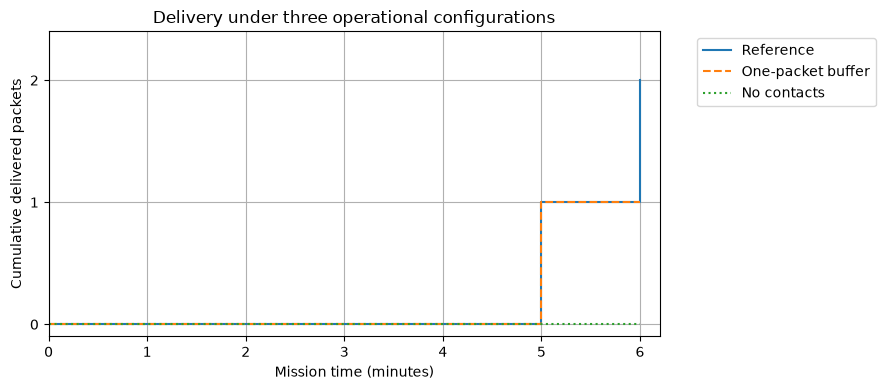

In [2]:
mission_histories = History()
mission_rows = {}
configurations = {
    "Reference": {},
    "One-packet buffer": {"buffer_capacity": 1},
    "No contacts": {"contact_times": ()},
}
for label, params in configurations.items():
    result, history = propagate.nominal(ObservationSatellite(p=params))
    mission_histories[label] = history
    counts = {
        key.removeprefix("tend.classify."): value for key, value in result.items()
    }
    mission_rows[label] = {
        key: counts[key] for key in ("selected", "downlinked", "queued", "dropped")
    }
    np.testing.assert_array_equal(
        history["fxns.process.s.selected"],
        history["fxns.downlink.s.downlinked"]
        + history["flows.buffer.s.queued"]
        + history["fxns.process.s.dropped"],
    )
mission_table = pd.DataFrame.from_dict(mission_rows, orient="index")
np.testing.assert_array_equal(mission_table["downlinked"], [2, 1, 0])
display(mission_table)

metric = "fxns.downlink.s.downlinked"
fig, axes = mission_histories.plot_line(
    metric,
    cols=1,
    comp_groups={label: (label,) for label in configurations},
    indiv_kwargs={
        "Reference": {"linestyle": "-"},
        "One-packet buffer": {"linestyle": "--"},
        "No contacts": {"linestyle": ":"},
    },
    drawstyle="steps-post",
    figsize=(9, 4),
    xlabel="Mission time (minutes)",
    ylabel="Cumulative delivered packets",
    titles={metric: "Delivery under three operational configurations"},
)
axes[0].set(xticks=range(7), yticks=[0, 1, 2], ylim=(-0.1, 2.4), xlim=(0, 6.2))
assert len(axes[0].lines) == len(configurations)
for line, label in zip(axes[0].lines, configurations):
    np.testing.assert_array_equal(line.get_ydata(), mission_histories[label][metric])
fig.tight_layout()
figures["delivery"] = fig
plt.show()

## Reference fault contributions

`run_risk_analysis` uses the existing `FaultSample → propagate.fault_sample → Result → FMEA` path. Each fault is injected at minute 1 or 3, with conditional time weights 0.25 and 0.75. Shortfall is `max(2 - downlinked, 0)` at minute 6.

Capture and processing failure each contribute `0.01 × (0.25 × 2 + 0.75 × 1) = 0.0125`; downlink failure contributes `0.01 × 2 = 0.02`. The total is **0.045 weighted missing packets** for this catalogue. The rates are synthetic, and this non-exhaustive single-fault contribution is not a total mission probability.

sum_scenario_rate  average_shortfall  expected_shortfall
downlink failed               0.01               2.00              0.0200
process  failed               0.01               1.25              0.0125
capture  failed               0.01               1.25              0.0125
         biased               0.02               0.00              0.0000

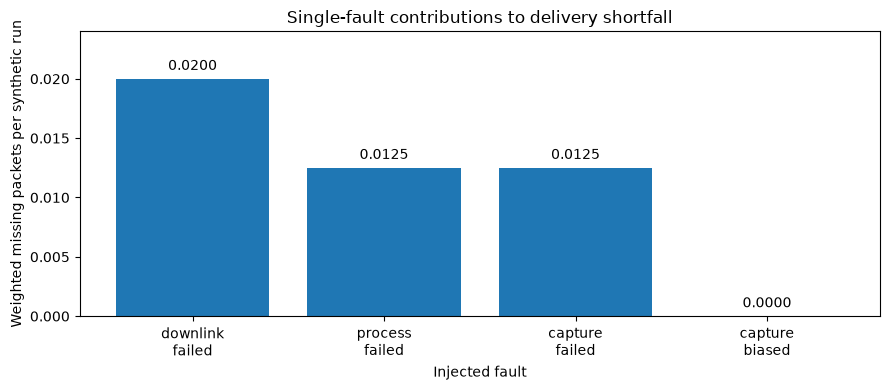

In [3]:
reference = run_risk_analysis()
reference.fmea.sort_by_factors()
reference.fmea.sort_by_metric("expected_shortfall", reverse=True)
reference_table = reference.fmea.as_table(sort=False)
display(
    reference_table[["sum_scenario_rate", "average_shortfall", "expected_shortfall"]]
)
np.testing.assert_allclose(sum(reference.fmea["expected_shortfall"].values()), 0.045)
np.testing.assert_allclose(sum(reference.fmea["sum_scenario_rate"].values()), 0.05)

fig, ax = reference.fmea.as_plot("expected_shortfall", xlab_ang=0, figsize=(9, 4))
ax.set(
    xlabel="Injected fault",
    ylabel="Weighted missing packets per synthetic run",
    title="Single-fault contributions to delivery shortfall",
    ylim=(0, 0.024),
)
contributions = reference.fmea["expected_shortfall"]
ax.set_xticks(
    range(len(contributions)), [f"{obj}\n{fault}" for obj, fault in contributions]
)
bars = next(item for item in ax.containers if isinstance(item, BarContainer))
ax.bar_label(bars, fmt="%.4f", padding=4)
np.testing.assert_allclose(
    [bar.get_height() for bar in bars], list(contributions.values())
)
fig.tight_layout()
figures["delivery_fmea"] = fig
plt.show()

## Variation across seeded disturbances

Every seed has equal Monte Carlo weight. No-fault and faulted runs share that seed, so their inputs are paired. The input probability densities are never used as additional sampling weights.

The histogram shows one complete fault-catalogue contribution per seed. Its spread is not a confidence interval. The standard error below is computed across the complete seed-level totals, retaining the pairing among faults within a seed. No-fault background losses are reported separately and must not simply be added to the catalogue contribution.

,Quantity,Packets
0,Catalogue contribution mean,0.052656
1,Monte Carlo standard error,0.002200
2,No-fault background mean shortfall,0.468750


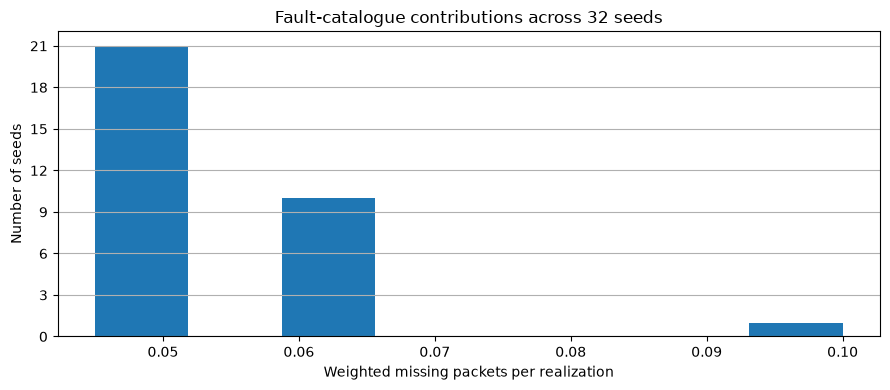

In [4]:
stochastic = run_risk_analysis(seeds, stochastic=True)
names = stochastic.sample.scen_names()
rates = stochastic.sample.get_scen_values("rate")
seed_contributions = Result(
    {
        f"seed_{seed}.catalogue_shortfall": stochastic.results.get(f"seed_{seed}")
        .get_scens(*names)
        .get_metric(
            "shortfall",
            method="expected",
            rates=rates,
            prefix="tend.classify.",
            round_value=False,
        )
        for seed in seeds
    }
)
values = np.asarray(list(seed_contributions.values()), dtype=float)
np.testing.assert_allclose(
    values.mean(), sum(stochastic.fmea["expected_shortfall"].values())
)
standard_error = (
    values.std(ddof=1) / np.sqrt(len(values)) if len(values) > 1 else np.nan
)
display(
    pd.DataFrame(
        {
            "Quantity": [
                "Catalogue contribution mean",
                "Monte Carlo standard error",
                "No-fault background mean shortfall",
            ],
            "Packets": [
                values.mean(),
                standard_error,
                stochastic.mean_result["nominal.tend.classify.shortfall"],
            ],
        }
    )
)
fig, axes = seed_contributions.plot_metric_dist(
    "catalogue_shortfall",
    comp_groups={"seeds": "default"},
    cols=1,
    bins=8,
    title="",
    xlabels={"catalogue_shortfall": "Weighted missing packets per realization"},
    ylabel="Number of seeds",
    figsize=(9, 4),
    legend_loc=False,
)
assert np.isclose(sum(bar.get_height() for bar in axes[0].patches), len(seeds))
axes[0].set_title(f"Fault-catalogue contributions across {len(seeds)} seeds")
axes[0].yaxis.set_major_locator(MaxNLocator(integer=True))
fig.tight_layout()
figures["seed_variation"] = fig
plt.show()

## Pixels reaching the external classifier

Switch to the already implemented `ClassifyingSatellite`. It trains scikit-learn's SVC on the first half of the bundled digits and uses held-out rows as mission inputs. The processor receives observed pixels only; truth labels are used by a separate evaluator.

Below, the **actual logged pixel arrays** are compared for a no-fault run and a payload brightness-bias fault at minute 1. A common-mode offset is clipped to [0, 1]. The image and prediction table describe this small fixed input sequence, not an accuracy benchmark. The same count-only buffer still cannot identify which targets were downlinked.

,Minute,Held-out row,Truth,No-fault prediction,Biased prediction
0,1,0,8,8,1
1,2,1,8,8,1
2,3,2,4,4,4
3,4,3,9,9,9


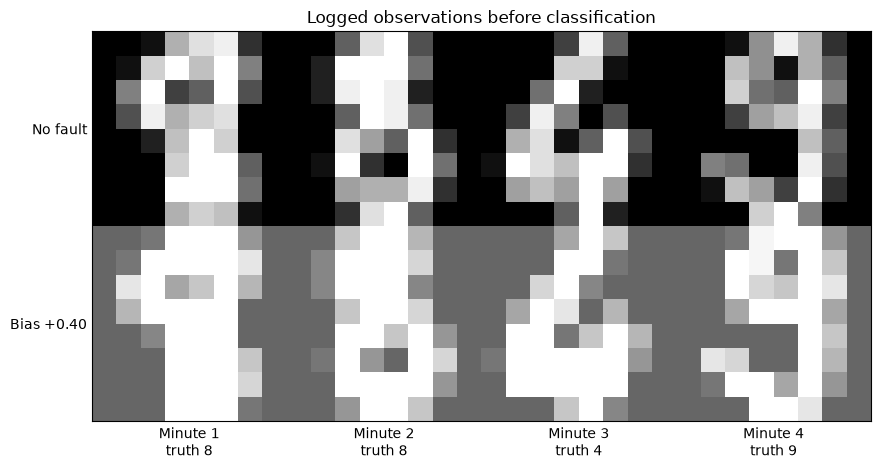

In [5]:
image_result, image_history, image_sample, image_fmea = run_classification_analysis(
    seed=image_seed,
    stochastic=False,
    params=image_params,
)
image_model = ClassifyingSatellite(p=image_params)
bias_scenario = next(
    s for s in image_sample.scenarios() if s.fault == "biased" and s.time == 1
)
traces = {
    "No fault": image_history.get("nominal"),
    "Payload bias": image_history.get(bias_scenario.name),
}
truth = heldout_digits()[1][list(image_model.p.image_indices)]
observed_rows = []
predictions = {}
for label, trace in traces.items():
    scheduled = np.isin(trace["time"], image_model.p.observation_times)
    assert trace["flows.observation.s.valid"][scheduled].all()
    observed = trace["flows.observation.s.pixels"][scheduled]
    observed_rows.append(
        np.concatenate([pixels.reshape(8, 8) for pixels in observed], axis=1)
    )
    predictions[label] = trace["fxns.process.s.predicted_label"][scheduled].astype(int)
    assert len(predictions[label]) == len(truth)
image_table = pd.DataFrame(
    {
        "Minute": image_model.p.observation_times,
        "Held-out row": image_model.p.image_indices,
        "Truth": truth,
        "No-fault prediction": predictions["No fault"],
        "Biased prediction": predictions["Payload bias"],
    }
)
display(image_table)

fig, ax = plt.subplots(figsize=(10, 4.8))
mosaic = np.concatenate(observed_rows, axis=0)
ax.imshow(mosaic, cmap="gray", vmin=0, vmax=1, interpolation="nearest")
ax.set_xticks(
    [3.5 + 8 * i for i in range(len(truth))],
    [
        f"Minute {t}\ntruth {label}"
        for t, label in zip(image_model.p.observation_times, truth)
    ],
)
ax.set_yticks([3.5, 11.5], ["No fault", f"Bias {image_model.p.bias:+.2f}"])
ax.set_title("Logged observations before classification")
ax.tick_params(length=0)
np.testing.assert_array_equal(ax.images[0].get_array(), mosaic)
fig.tight_layout()
figures["observed_images"] = fig
plt.show()

## Detection outcomes and unavailable observations

The target class is digit 8. Detection false negatives mean a classified target was rejected; `unclassified_targets` records target observations that never received a prediction. Their sum is `missed_targets`. Ten-class prediction errors are a separate quantity: a wrong digit may still produce the correct keep/discard decision.

The table includes the no-fault reference, bias, and a processing outage. The FMEA plot aggregates injection times and applies the synthetic fault rates once. It concerns onboard selection only, not delivered target identity or real mission reliability.

,true_positives,false_positives,false_negatives,unclassified_targets,missed_targets,downlinked
No fault,2,0,0,0,0,2
Payload bias at 1,0,0,2,0,2,0
Processor failed at 1,0,0,0,2,2,0


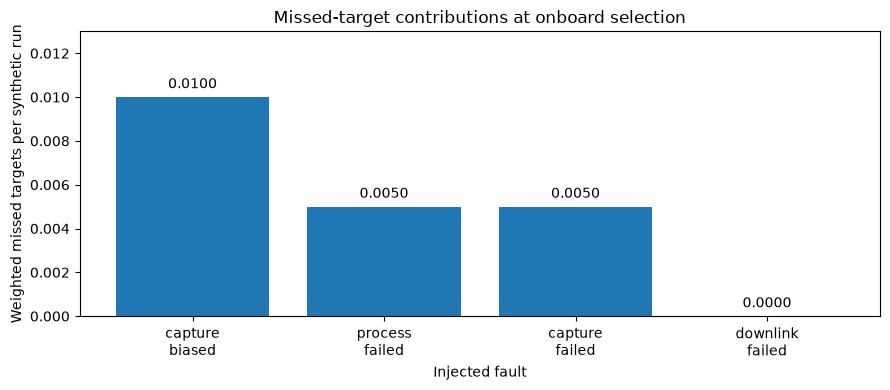

In [6]:
processing_scenario = next(
    s for s in image_sample.scenarios() if s.obj == "process" and s.time == 1
)
scenario_labels = {
    "No fault": "nominal",
    "Payload bias at 1": bias_scenario.name,
    "Processor failed at 1": processing_scenario.name,
}
columns = [
    "true_positives",
    "false_positives",
    "false_negatives",
    "unclassified_targets",
    "missed_targets",
    "downlinked",
]
outcomes = pd.DataFrame(
    {
        label: {key: image_result[f"{name}.tend.classify.{key}"] for key in columns}
        for label, name in scenario_labels.items()
    }
).T
display(outcomes)
for name in ["nominal", *image_sample.scen_names()]:
    counts = image_result.get(name)

    def key(field):
        return counts["tend.classify." + field]

    assert key("missed_targets") == key("false_negatives") + key("unclassified_targets")
    assert sum(
        key(field)
        for field in (
            "true_positives",
            "false_positives",
            "true_negatives",
            "false_negatives",
            "unclassified",
        )
    ) == key("opportunities")
    assert key("selected") == key("downlinked") + key("queued") + key("dropped")

image_fmea.sort_by_factors()
image_fmea.sort_by_metric("expected_missed_targets", reverse=True)
classification_table = image_fmea.as_table(sort=False)
fig, ax = image_fmea.as_plot("expected_missed_targets", xlab_ang=0, figsize=(9, 4))
ax.set(
    xlabel="Injected fault",
    ylabel="Weighted missed targets per synthetic run",
    title="Missed-target contributions at onboard selection",
)
detection_contributions = image_fmea["expected_missed_targets"]
ax.set_xticks(
    range(len(detection_contributions)),
    [f"{obj}\n{fault}" for obj, fault in detection_contributions],
)
heights = np.asarray(list(detection_contributions.values()))
ax.set_ylim(0, max(heights.max() * 1.3, 0.001))
bars = next(item for item in ax.containers if isinstance(item, BarContainer))
ax.bar_label(bars, fmt="%.4f", padding=4)
np.testing.assert_allclose([bar.get_height() for bar in bars], heights)
fig.tight_layout()
figures["detection_fmea"] = fig
plt.show()

## Checks and export

The preceding cells check packet conservation, the analytical 0.045 reference, seed-weight reconciliation, classification accounting and plotted arrays. This CSV round trip confirms that exporting the table preserves its values. No files are written unless you explicitly enable the final export cell.

For every figure, keep the corresponding assumptions and source outputs. In particular, never label a synthetic catalogue contribution as total mission-failure probability.

In [7]:
csv = reference_table.to_csv()
restored = pd.read_csv(io.StringIO(csv), index_col=[0, 1])
np.testing.assert_allclose(
    restored["expected_shortfall"], reference_table["expected_shortfall"]
)
assert set(figures) == {
    "delivery",
    "delivery_fmea",
    "seed_variation",
    "observed_images",
    "detection_fmea",
}
print(
    f"Checked {len(figures)} figures, {len(seeds)} disturbance seeds and {len(image_sample.scen_names())} classification fault scenarios."
)

Checked 5 figures, 32 disturbance seeds and 8 classification fault scenarios.


Set `export_directory` to a **new directory** to save the five figures and exact tables. The default leaves the filesystem unchanged; an existing directory is rejected to avoid overwriting earlier results.

In [8]:
from pathlib import Path

export_directory = None  # Example: Path("satellite-demo-output")
if export_directory is not None:
    destination = Path(export_directory)
    destination.mkdir(parents=True, exist_ok=False)
    for name, figure in figures.items():
        figure.savefig(destination / f"{name}.png", dpi=160, bbox_inches="tight")
    mission_table.to_csv(destination / "mission-counts.csv")
    reference_table.to_csv(destination / "delivery-fmea.csv")
    stochastic.fmea.as_table().to_csv(destination / "stochastic-delivery-fmea.csv")
    pd.DataFrame({"seed": seeds, "catalogue_shortfall": values}).to_csv(
        destination / "seed-contributions.csv", index=False
    )
    image_table.to_csv(destination / "image-predictions.csv", index=False)
    outcomes.to_csv(destination / "classification-outcomes.csv")
    classification_table.to_csv(destination / "classification-fmea.csv")
    print("Exported to", destination.resolve())

## Continue with the focused examples

- [Nominal model](example.ipynb) for complete reference histories and operating configurations.
- [Risk and FMEA](demo_risk_analysis.ipynb) for scenario weights, paired histories and result exports.
- [Classification implementation](classification.rst) for train/test separation, error definitions and the pixel-only inference boundary.
- [Visualisation guide](visualisation.rst) for reproducible execution, output interpretation and troubleshooting.

This walkthrough reuses the existing models. Calibrated planetary data, a complete mission-risk model and the general external-simulator interface remain separate work.